In [2]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import random
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Categorical, Normal
import os
import matplotlib.pyplot as plt
import importlib.util
import inspect
import glob
import sys
from pathlib import Path # Import Path for robust path handling

# --- Path Calculations for Jupyter Notebooks ---
# Assuming the notebook is in 'KYX_PARSER/test/'
# SCRIPT_DIR will be 'KYX_PARSER/test/'
SCRIPT_DIR = Path(os.getcwd())
print(f"Notebook's current working directory: {SCRIPT_DIR.resolve()}")

# PROJECT_ROOT will be 'KYX_PARSER/'
PROJECT_ROOT = SCRIPT_DIR.parent
print(f"Project Root: {PROJECT_ROOT.resolve()}")

# Define the directory containing 'ast_config.py' (e.g., 'KYX_PARSER/AST_parser/')
# Adjust "AST_parser" if your actual directory name is different (e.g., "Ast_parser" as in your original snippet)
parser_module_dir = PROJECT_ROOT / "AST_parser"
print(f"Parser Module Directory: {parser_module_dir.resolve()}")

# Add the parser module directory to Python's system path
# This allows direct import of modules within AST_parser (like ast_config)
if str(parser_module_dir) not in sys.path:
    sys.path.insert(0, str(parser_module_dir))
    print(f"Added '{parser_module_dir.resolve()}' to sys.path.")
else:
    print(f"'{parser_module_dir.resolve()}' already in sys.path.")

# --- End Path Calculations ---

# Ensure ast_config is available if generated environments need it
# Now that 'parser_module_dir' is in sys.path, we can directly import ast_config
try:
    import ast_config
    print("ast_config.py imported successfully.")
except ImportError as e:
    print(f"Warning: ast_config.py not found. Error: {e}")
    print(f"Please ensure ast_config.py is located in: {parser_module_dir.resolve()}")
    print("If your generated environments depend on it, they might fail to load.")


# --- Constants for training ---
GAMMA = 0.99  # Discount factor for rewards
LR_ACTOR = 0.0005 # Learning rate for the actor
LR_CRITIC = 0.001 # Learning rate for the critic
CLIP_GRAD_NORM = 0.5 # Gradient clipping to prevent exploding gradients

Notebook's current working directory: D:\Reinforcement learning\kyx_parser\test
Project Root: D:\Reinforcement learning\kyx_parser
Parser Module Directory: D:\Reinforcement learning\kyx_parser\AST_parser
Added 'D:\Reinforcement learning\kyx_parser\AST_parser' to sys.path.
ast_config.py imported successfully.


In [3]:
# --- Neural Network Definitions ---
class Actor(nn.Module):
    def __init__(self, obs_dim, discrete_action_dim, continuous_action_dim):
        super(Actor, self).__init__()
        self.fc1 = nn.Linear(obs_dim, 128)
        self.fc2 = nn.Linear(128, 128)

        self.discrete_action_dim = discrete_action_dim
        self.continuous_action_dim = continuous_action_dim

        # Conditionally create discrete head
        if self.discrete_action_dim > 0:
            self.discrete_head = nn.Linear(128, self.discrete_action_dim)
        else:
            self.discrete_head = None

        # Conditionally create continuous heads
        if self.continuous_action_dim > 0:
            self.continuous_mean_head = nn.Linear(128, self.continuous_action_dim)
            # Initialize log_std to a small negative value
            self.continuous_log_std_head = nn.Parameter(torch.zeros(1, self.continuous_action_dim))
        else:
            self.continuous_mean_head = None
            self.continuous_log_std_head = None

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))

        discrete_logits = None
        continuous_means = None
        continuous_log_stds = None

        if self.discrete_head is not None:
            discrete_logits = self.discrete_head(x)

        if self.continuous_mean_head is not None:
            continuous_means = self.continuous_mean_head(x)
            # Expand log_std to match the batch size and action dimension of means.
            continuous_log_stds = self.continuous_log_std_head.expand_as(continuous_means).clamp(-20, 2)
        
        return discrete_logits, continuous_means, continuous_log_stds

class Critic(nn.Module):
    def __init__(self, obs_dim):
        super(Critic, self).__init__()
        self.fc1 = nn.Linear(obs_dim, 128)
        self.fc2 = nn.Linear(128, 128)
        self.value_head = nn.Linear(128, 1)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        return self.value_head(x)

In [4]:
# --- Learning Agent Definition (A2C-like) ---
class LearningAgent:
    def __init__(self, env, model_dir="models"):
        self.env = env
        self.model_dir = model_dir
        os.makedirs(self.model_dir, exist_ok=True)

        self.obs_dim = env.observation_space.shape[0]

        # Dynamically determine discrete and continuous action dimensions and their keys
        self.discrete_action_dim = 0
        self.continuous_action_dim = 0
        self.discrete_action_key = None
        self.continuous_action_keys = []
        self.continuous_action_component_shapes = {} # To store original shapes for reconstruction

        if isinstance(env.action_space, spaces.Dict):
            for key, space in env.action_space.items():
                if isinstance(space, spaces.Discrete):
                    if self.discrete_action_key is not None:
                        # print(f"Warning: Multiple discrete action spaces found. Using the first one identified ('{self.discrete_action_key}').")
                        pass # Suppress warning for cleaner output in notebook
                    else:
                        self.discrete_action_dim = space.n
                        self.discrete_action_key = key
                elif isinstance(space, spaces.Box):
                    # Handle scalar Box spaces (shape=()) correctly
                    component_size = space.shape[0] if space.shape else 1
                    self.continuous_action_dim += component_size
                    self.continuous_action_component_shapes[key] = component_size
                    self.continuous_action_keys.append(key)
            
            if self.discrete_action_key is None:
                print("Info: No discrete action space found in the environment's action_space Dict.")
            if not self.continuous_action_keys:
                print("Info: No continuous action spaces found in the environment's action_space Dict.")
        else:
            raise TypeError(f"Environment action space is of type {type(env.action_space)}, but LearningAgent expects a gymnasium.spaces.Dict space.")

        if self.discrete_action_dim == 0 and self.continuous_action_dim == 0:
            raise ValueError("Could not determine any action dimensions from the environment's action space. Check its definition.")

        self.actor = Actor(self.obs_dim, self.discrete_action_dim, self.continuous_action_dim)
        self.critic = Critic(self.obs_dim)

        self.actor_optimizer = optim.Adam(self.actor.parameters(), lr=LR_ACTOR)
        self.critic_optimizer = optim.Adam(self.critic.parameters(), lr=LR_CRITIC)

        self.log_probs = []
        self.values = []
        self.rewards = []
        self.masks = []

    def get_action(self, observation):
        obs_tensor = torch.FloatTensor(observation).unsqueeze(0)
        discrete_logits, continuous_means, continuous_log_stds = self.actor(obs_tensor)

        action = {}
        # Initialize total_log_prob as a tensor with a batch dimension (1,)
        total_log_prob = torch.zeros(1, device=obs_tensor.device) 

        # --- Discrete action sampling ---
        if self.discrete_action_key is not None:
            discrete_dist = Categorical(logits=discrete_logits)
            discrete_action = discrete_dist.sample() # Shape (1,)
            action[self.discrete_action_key] = discrete_action.item()
            total_log_prob += discrete_dist.log_prob(discrete_action) # Shape (1,)

        # --- Continuous action sampling ---
        if self.continuous_action_keys:
            continuous_stds = torch.exp(continuous_log_stds)
            continuous_dist = Normal(continuous_means, continuous_stds)
            continuous_actions_tensor = continuous_dist.sample() # Shape: (1, self.continuous_action_dim)
            
            # Calculate log-probability for continuous actions. Sum over the action dimensions.
            total_log_prob += continuous_dist.log_prob(continuous_actions_tensor).sum(dim=-1) # Shape (1,)

            # Assign continuous actions back to their original keys
            current_idx = 0
            for key in self.continuous_action_keys:
                component_size = self.continuous_action_component_shapes[key]
                component_value_tensor = continuous_actions_tensor[0, current_idx : current_idx + component_size]
                
                if component_size == 1:
                    action[key] = np.float64(component_value_tensor.item())
                else:
                    # If a Box space was shape=(N,), then it would be an array.
                    action[key] = component_value_tensor.cpu().numpy().astype(np.float64)
                
                current_idx += component_size
        
        value = self.critic(obs_tensor)
        self.log_probs.append(total_log_prob)
        self.values.append(value)
        
        # Fill in dummy values for any Box spaces not covered by continuous_action_keys
        # This is crucial because the environment expects ALL keys in the Dict action space.
        if isinstance(self.env.action_space, spaces.Dict):
            for key, space in self.env.action_space.items():
                if key not in action:
                    if isinstance(space, spaces.Discrete):
                        action[key] = 0 # Default discrete choice
                    elif isinstance(space, spaces.Box):
                        action[key] = space.sample() # Sample from the box space
        
        return action

    def store_transition(self, reward, terminated, truncated):
        self.rewards.append(reward)
        self.masks.append(1.0 - (terminated or truncated))

    def learn(self, next_observation):
        if not self.rewards: # No steps taken in episode, nothing to learn
            return

        log_probs = torch.cat(self.log_probs)
        values = torch.cat(self.values)
        rewards = torch.FloatTensor(self.rewards)
        masks = torch.FloatTensor(self.masks)

        next_obs_tensor = torch.FloatTensor(next_observation).unsqueeze(0)
        next_value = self.critic(next_obs_tensor).detach()

        returns = torch.zeros_like(rewards)
        R = next_value * masks[-1]

        for t in reversed(range(len(rewards))):
            R = rewards[t] + GAMMA * R * masks[t]
            returns[t] = R

        advantages = returns - values.squeeze()

        # --- Actor Loss ---
        actor_loss = -(log_probs * advantages.detach()).mean()
        
        # --- Critic Loss ---
        critic_loss = advantages.pow(2).mean()

        # --- Update Actor Network ---
        self.actor_optimizer.zero_grad()
        actor_loss.backward()
        nn.utils.clip_grad_norm_(self.actor.parameters(), CLIP_GRAD_NORM)
        self.actor_optimizer.step()

        # --- Update Critic Network ---
        self.critic_optimizer.zero_grad()
        critic_loss.backward()
        nn.utils.clip_grad_norm_(self.critic.parameters(), CLIP_GRAD_NORM)
        self.critic_optimizer.step()

        # Clear buffers
        self.log_probs = []
        self.values = []
        self.rewards = []
        self.masks = []

    def save_weights(self, episode_num=None, env_name="default"):
        model_dir_env = os.path.join(self.model_dir, env_name)
        os.makedirs(model_dir_env, exist_ok=True)
        actor_path = os.path.join(model_dir_env, f"actor_weights_ep{episode_num}.pth" if episode_num else "actor_weights_final.pth")
        critic_path = os.path.join(model_dir_env, f"critic_weights_ep{episode_num}.pth" if episode_num else "critic_weights_final.pth")
        torch.save(self.actor.state_dict(), actor_path)
        torch.save(self.critic.state_dict(), critic_path)
        # print(f"Saved actor weights to {actor_path}")
        # print(f"Saved critic weights to {critic_path}")

    def load_weights(self, episode_num=None, env_name="default"):
        model_dir_env = os.path.join(self.model_dir, env_name)
        actor_path = os.path.join(model_dir_env, f"actor_weights_ep{episode_num}.pth" if episode_num else "actor_weights_final.pth")
        critic_path = os.path.join(model_dir_env, f"critic_weights_ep{episode_num}.pth" if episode_num else "critic_weights_final.pth")
        
        if os.path.exists(actor_path) and os.path.exists(critic_path):
            self.actor.load_state_dict(torch.load(actor_path))
            self.critic.load_state_dict(torch.load(critic_path))
            print(f"Loaded weights for {env_name} from episode {episode_num if episode_num else 'final'}.")
            return True
        else:
            # print(f"No weights found for {env_name} at {actor_path} and {critic_path}. Starting from scratch.")
            return False

In [5]:
# --- Helper function to run training for a single environment ---
def run_training_for_env(env_class, env_name_for_display, 
                         num_episodes=2000, max_steps_per_episode=100, 
                         save_interval=200, load_existing_weights=False, evaluate_only=False):
    
    print(f"\n--- Starting Training for Environment: {env_name_for_display} ---")

    env = env_class()
    agent = LearningAgent(env, model_dir=f"models/{env_name_for_display}") 

    if load_existing_weights or evaluate_only:
        agent.load_weights(env_name=env_name_for_display)

    total_steps_taken = 0
    episode_rewards = []

    for episode in range(num_episodes):
        observation, info = env.reset()
        
        # Set constants after reset, as per your example
        env.constants['W'] = 1.0
        env.constants['A'] = 1.0
        env.constants['b'] = 0.5
        env.constants['ep'] = 1.0
        
        episode_reward = 0.0
        episode_steps = 0
        
        for step in range(max_steps_per_episode):
            action = agent.get_action(observation) 
            
            next_observation, reward, terminated, truncated, info = env.step(action)
            
            if not evaluate_only:
                agent.store_transition(reward, terminated, truncated)
            
            observation = next_observation
            episode_reward += reward
            episode_steps += 1
            total_steps_taken += 1
            
            if terminated or truncated:
                break
        
        if not evaluate_only:
            agent.learn(observation) 
        
        episode_rewards.append(episode_reward)
        
        avg_reward_last_100 = np.mean(episode_rewards[-100:])
        if (episode + 1) % 100 == 0: # Print progress every 100 episodes
            print(f"  Episode {episode + 1}/{num_episodes}, Steps: {episode_steps}, Total Reward: {episode_reward:.2f}, Avg Reward (last 100): {avg_reward_last_100:.2f}")

        if (episode + 1) % save_interval == 0 and not evaluate_only:
            agent.save_weights(episode + 1, env_name=env_name_for_display)

    if not evaluate_only:
        agent.save_weights(env_name=env_name_for_display)

    env.close()

    print(f"--- Simulation Summary for {env_name_for_display} ---")
    print(f"Total Episodes Run: {num_episodes}")
    print(f"Total Steps Across All Episodes: {total_steps_taken}")
    if episode_rewards:
        print(f"Average Reward over last 100 episodes: {np.mean(episode_rewards[-100:]):.2f}")
        print(f"Max Reward achieved: {np.max(episode_rewards):.2f}")
    
    return episode_rewards

In [13]:
# --- Main Execution: Discover and Run All Environments ---

# Define the directory where generated environments are located
# CORRECTED: Use SCRIPT_DIR (which is an absolute Path object) to build ENV_DIR
ENV_DIR = SCRIPT_DIR / "output_python" # This will correctly resolve to KYX_PARSER/test/output_python/

# Configuration for training all environments
NUM_EPISODES = 1000
MAX_STEPS_PER_EPISODE = 100
SAVE_INTERVAL = 500
LOAD_EXISTING_WEIGHTS = False
EVALUATE_ONLY = False

all_env_rewards = {}

# Add the environment directory to the Python path temporarily
# Ensure we add the string representation of the absolute Path object
if str(ENV_DIR) not in sys.path:
    sys.path.insert(0, str(ENV_DIR))
    print(f"Added environment directory to sys.path: {ENV_DIR.resolve()}")
else:
    print(f"Environment directory already in sys.path: {ENV_DIR.resolve()}")


# Find all Python files in the specified directory
# glob.glob now receives an absolute path
env_files = glob.glob(str(ENV_DIR / '*.py')) # Convert Path object to string for glob.glob

if not env_files:
    print(f"No environment files found in {ENV_DIR.resolve()}. Please check the path.")
else:
    print(f"Found {len(env_files)} environment files in {ENV_DIR.resolve()}.")

for file_path in env_files:
    module_name = os.path.splitext(os.path.basename(file_path))[0]
    
    try:
        # Dynamically import the module
        spec = importlib.util.spec_from_file_location(module_name, file_path)
        module = importlib.util.module_from_spec(spec)
        spec.loader.exec_module(module)

        # Find the Gymnasium environment class within the module
        env_class = None
        for name, obj in inspect.getmembers(module):
            # Check if it's a class, a subclass of gym.Env, and not gym.Env itself
            if inspect.isclass(obj) and issubclass(obj, gym.Env) and obj is not gym.Env:
                env_class = obj
                break

        if env_class:
            env_name_for_display = env_class.__name__ # Get the actual class name
            print(f"\n--- Discovered Environment: {env_name_for_display} from {file_path} ---")
            
            # --- IMPORTANT ---
            # The function `run_training_for_env` is not defined in the provided snippets.
            # You'll need to ensure this function is defined in a previous cell or imported.
            # For demonstration, I'll assume it exists.
            
            rewards = run_training_for_env(env_class, env_name_for_display,
                                           num_episodes=NUM_EPISODES,
                                           max_steps_per_episode=MAX_STEPS_PER_EPISODE,
                                           save_interval=SAVE_INTERVAL,
                                           load_existing_weights=LOAD_EXISTING_WEIGHTS,
                                           evaluate_only=EVALUATE_ONLY)
            
            # Placeholder for actual training call
            # print(f"Would now run training for {env_name_for_display}...")
            # rewards = run_training_for_env(...) # Uncomment when run_training_for_env is defined
            all_env_rewards[env_name_for_display] = rewards
            
        else:
            print(f"No Gymnasium environment class found in {file_path}. Skipping.")

    except Exception as e:
        print(f"Error loading or running environment from {file_path}: {e}")

# Remove the environment directory from the Python path
# It's good practice to remove it if you only needed it temporarily.
# However, if other parts of your notebook might still need it, you might keep it.
# The pop(0) assumes it was inserted at index 0.
if sys.path[0] == str(ENV_DIR): # Check if it's still at the first position
    sys.path.pop(0)
    print(f"Removed environment directory from sys.path: {ENV_DIR.resolve()}")
else:
    print("Environment directory not found at sys.path[0] for removal.")

Added environment directory to sys.path: D:\Reinforcement learning\kyx_parser\test\output_python
Found 3 environment files in D:\Reinforcement learning\kyx_parser\test\output_python.

--- Discovered Environment: IJRR17_Theorem_1__Static_safety from d:\Reinforcement learning\kyx_parser\test\output_python\test1.py ---

--- Starting Training for Environment: IJRR17_Theorem_1__Static_safety ---
  Episode 100/1000, Steps: 1, Total Reward: -100.00, Avg Reward (last 100): -132.97
  Episode 200/1000, Steps: 1, Total Reward: -100.00, Avg Reward (last 100): -116.98
  Episode 300/1000, Steps: 1, Total Reward: -100.00, Avg Reward (last 100): -108.99
  Episode 400/1000, Steps: 1, Total Reward: -100.00, Avg Reward (last 100): -102.00
  Episode 500/1000, Steps: 1, Total Reward: -100.00, Avg Reward (last 100): -102.00
  Episode 600/1000, Steps: 1, Total Reward: -100.00, Avg Reward (last 100): -100.00
  Episode 700/1000, Steps: 1, Total Reward: -100.00, Avg Reward (last 100): -100.00
  Episode 800/1000


--- Overall Training Results ---


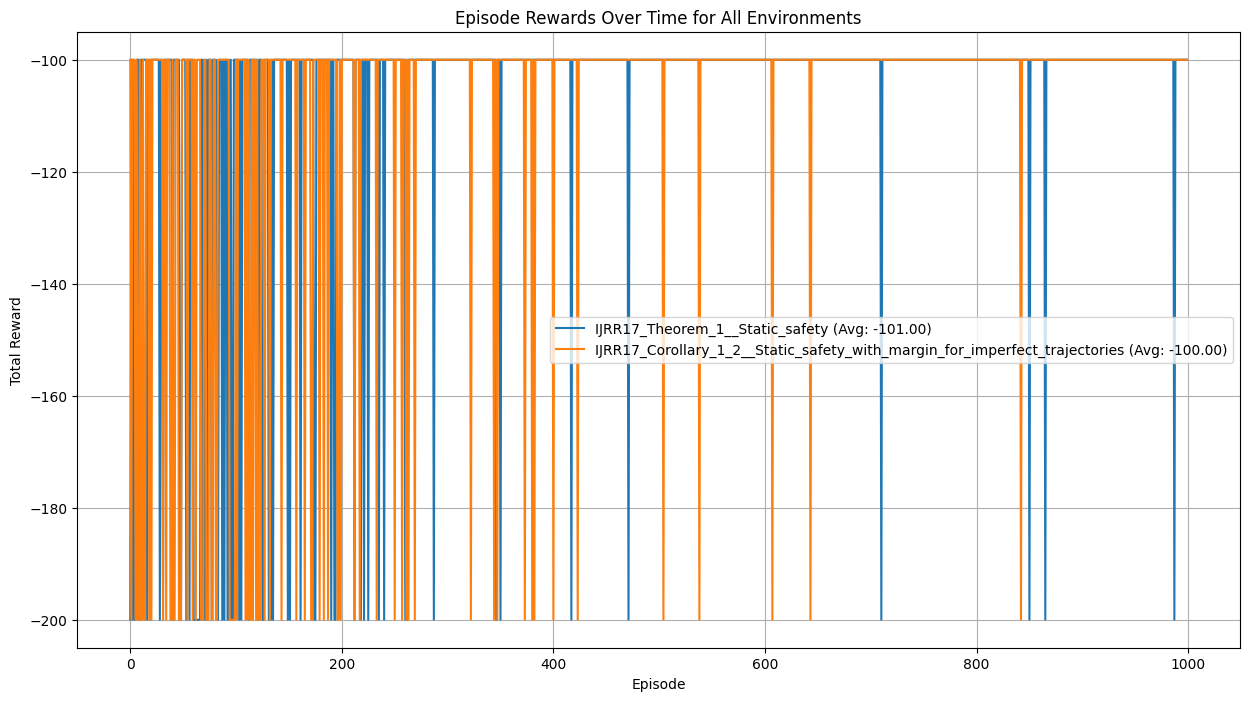

: 

In [ ]:
# --- Plotting Results for All Environments ---
print("\n--- Overall Training Results ---")

if all_env_rewards:
    plt.figure(figsize=(15, 8))
    for env_name, rewards in all_env_rewards.items():
        if rewards:
            plt.plot(rewards, label=f'{env_name} (Avg: {np.mean(rewards[-100:]):.2f})')
    
    plt.title('Episode Rewards Over Time for All Environments')
    plt.xlabel('Episode')
    plt.ylabel('Total Reward')
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print("No environments were successfully processed to generate rewards.")